# Chapter 54 — RAG Architecture: Ingestion, Retrieval and Generation

Project: Build an end-to-end RAG pipeline
This standalone notebook builds a RAG pipeline in three stages:
1. Ingestion: prepare source documents, split them into chunks, embed the chunks, and store their vectors.
2. Retrieval: embed a user question and retrieve relevant chunks from FAISS.
3. Generation: send the question and retrieved context to a Groq-hosted LLM.
You will learn how to keep source IDs, inspect retrieved evidence, and separate each stage for easier debugging. The policy documents are fictional examples, not real compliance guidance. This notebook does not depend on variables or files from earlier chapters.

# 1. Install libraries

In [ ]:
%pip install -q sentence-transformers faiss-cpu numpy pandas openai

# 2. Import libraries

In [34]:
import os
from getpass import getpass
import faiss
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from openai import OpenAI


Unlike the standard input() function, which displays characters on the screen as you type, getpass turns off terminal echoing. This prevents onlookers from seeing what is being typed (a security risk known as "shoulder surfing").

# 3. Create fictional source documents

In [35]:
source_documents = [
    {
        "source_id": "POLICY-001",
        "title": "Cross-border alert review",
        "text": (
            "Northstar Bank is fictional. Standard cross-border transaction alerts "
            "must receive an initial review within 24 hours of creation. The reviewer "
            "must inspect available transaction details and document the decision. "
            "Potentially urgent cases must be escalated promptly; the 24-hour target "
            "does not replace urgent escalation."
        )
    },
    {
        "source_id": "POLICY-002",
        "title": "High-risk alert handling",
        "text": (
            "In this fictional policy, alerts classified as high risk require a "
            "second-level review by a senior investigator before closure. The case "
            "notes must explain why the alert was escalated and summarize the evidence "
            "considered by both reviewers."
        )
    },
    {
        "source_id": "POLICY-003",
        "title": "Case documentation and closure",
        "text": (
            "Investigators must record the rationale for a decision, the evidence "
            "reviewed, and the case disposition. An alert may be closed only after "
            "available evidence has been reviewed and the reason for closure has been "
            "documented. Missing customer information must be recorded as a gap; "
            "investigators must not invent missing details."
        )
    },
    {
        "source_id": "POLICY-004",
        "title": "Quality assurance",
        "text": (
            "A sample of closed alerts is reviewed each month to assess decision "
            "quality, evidence sufficiency, and consistency with the fictional policy. "
            "Findings are documented and recurring issues are referred to the "
            "appropriate process owner for remediation."
        )
    }
]
pd.DataFrame(source_documents)

,source_id,title,text
0,POLICY-001,Cross-border alert review,Northstar Bank is fictional. Standard cross-bo...
1,POLICY-002,High-risk alert handling,"In this fictional policy, alerts classified as..."
2,POLICY-003,Case documentation and closure,Investigators must record the rationale for a ...
3,POLICY-004,Quality assurance,A sample of closed alerts is reviewed each mon...


# 4. Define a simple chunking function

Chunking splits longer text into smaller pieces. This beginner-friendly function uses word counts and overlap. Production systems may use token-aware or structure-aware chunking.

In [36]:
def chunk_text(text: str, chunk_size : int = 45, overlap: int = 8) -> list[str]:
    if not isinstance(text, str) or not text.strip():
        raise ValueError("text must be a non-empty string")
    if not isinstance(chunk_size, int) or chunk_size <= 0:
        raise ValueError("Chunk size must be a positive integer")
    if not isinstance(overlap, int) or overlap < 0:
        raise ValueError("overlap must be a non-negative integer")
    if overlap >= chunk_size:
        raise ValueError("Overlap must be a smaller than chunk_size")

    words = text.split()
    chunks = []
    start = 0
    while start < len(words):
        end = start + chunk_size 
        chunks.append(" ".join(words[start:end]))
        if end >=len(words):
            break
        start = end - overlap
    return chunks

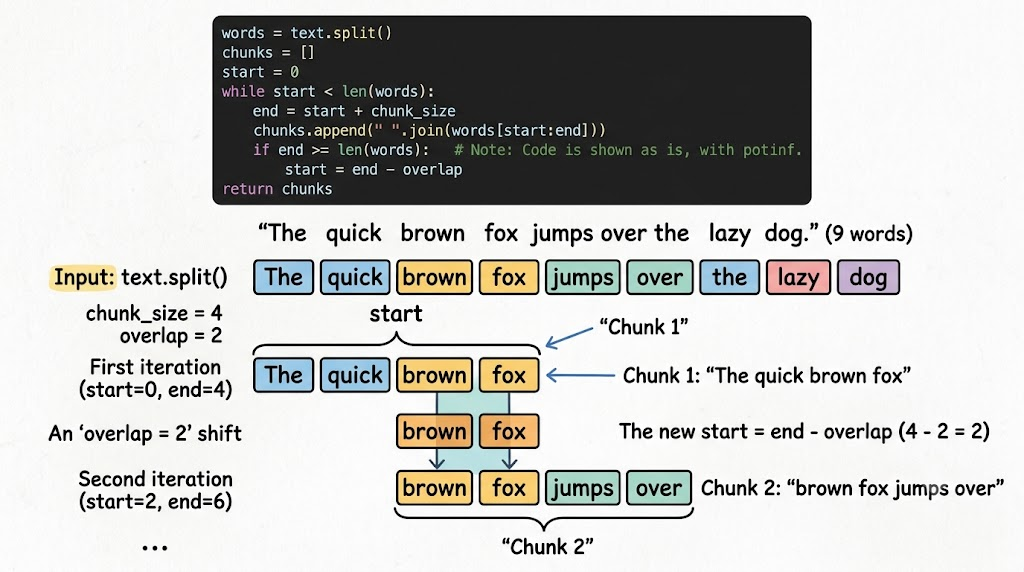

In [37]:
chunk_text("one, two  three four five six seven eight neine, ten ", chunk_size = 5, overlap = 2)

['one, two three four five',
 'four five six seven eight',
 'seven eight neine, ten']

# 5. Run ingestion

Each chunk keeps its source ID, title and chunk number so retrieved results can be traced back to their source.

In [38]:
source_documents

[{'source_id': 'POLICY-001',
  'title': 'Cross-border alert review',
  'text': 'Northstar Bank is fictional. Standard cross-border transaction alerts must receive an initial review within 24 hours of creation. The reviewer must inspect available transaction details and document the decision. Potentially urgent cases must be escalated promptly; the 24-hour target does not replace urgent escalation.'},
 {'source_id': 'POLICY-002',
  'title': 'High-risk alert handling',
  'text': 'In this fictional policy, alerts classified as high risk require a second-level review by a senior investigator before closure. The case notes must explain why the alert was escalated and summarize the evidence considered by both reviewers.'},
 {'source_id': 'POLICY-003',
  'title': 'Case documentation and closure',
  'text': 'Investigators must record the rationale for a decision, the evidence reviewed, and the case disposition. An alert may be closed only after available evidence has been reviewed and the reas

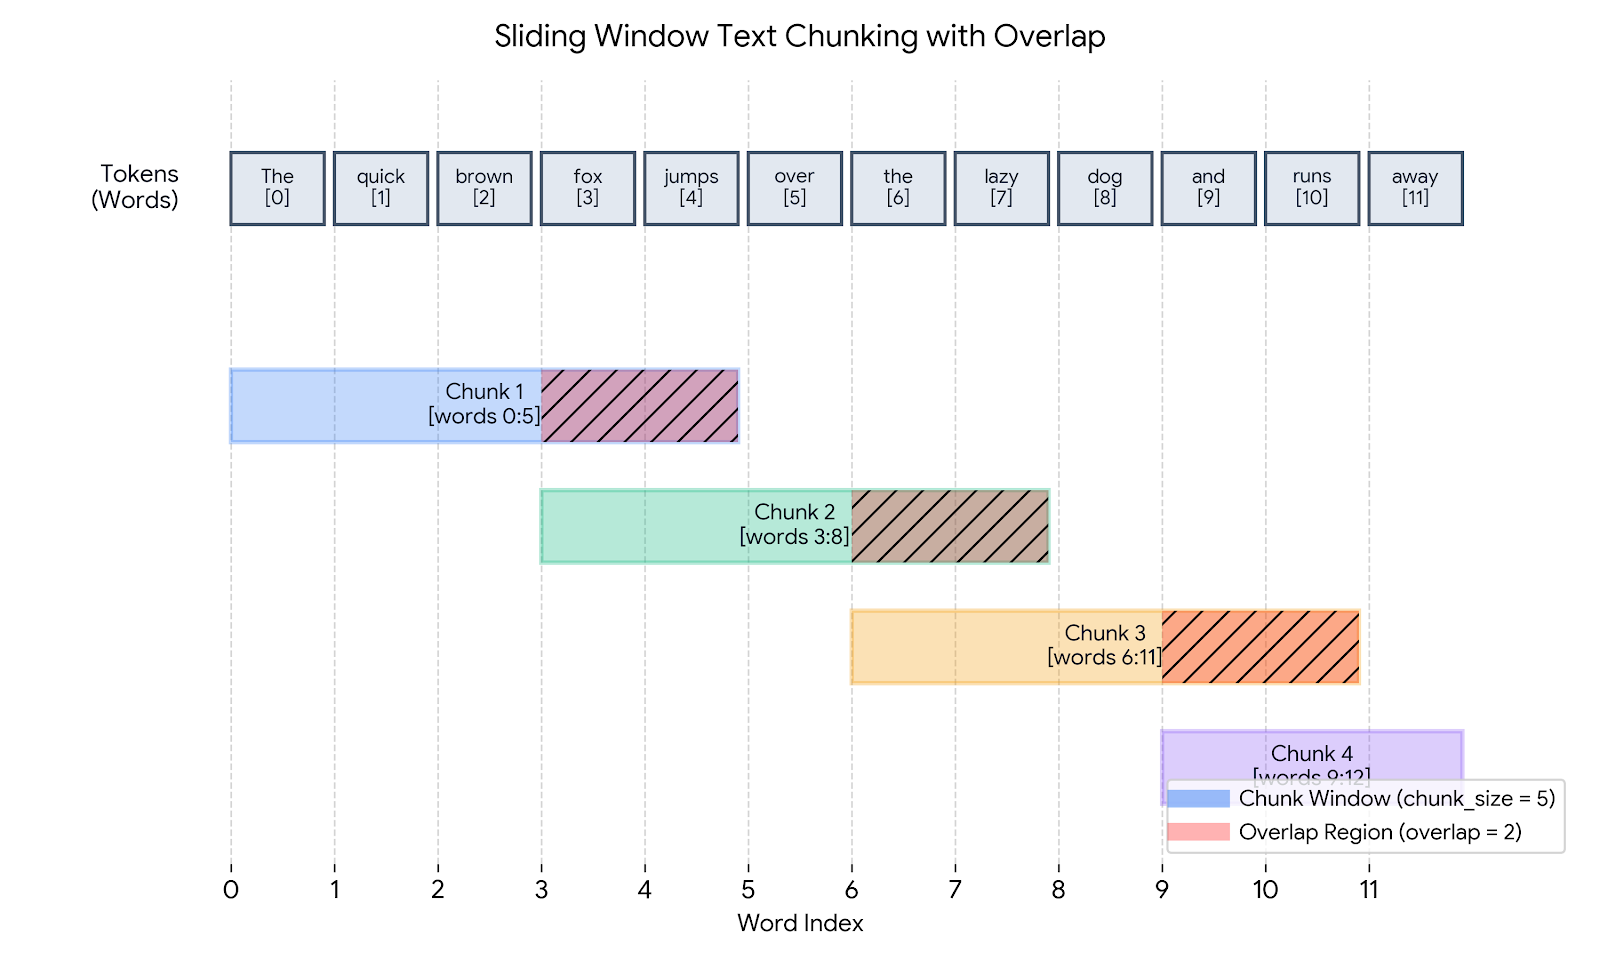

In [39]:
chunks = []
for document in source_documents:
    document_chunks = chunk_text(document["text"], chunk_size=45, overlap=8)
    for chunk_number, chunk in enumerate(document_chunks):
        chunks.append({
            "chunk_id": f"{document['source_id']}-CHUNK-{chunk_number:03d}",
            "source_id": document["source_id"],
            "title": document["title"],
            "chunk_number": chunk_number,
            "text": chunk
        })

chunks_df = pd.DataFrame(chunks)


In [40]:
display(chunks_df)


,chunk_id,source_id,title,chunk_number,text
0,POLICY-001-CHUNK-000,POLICY-001,Cross-border alert review,0,Northstar Bank is fictional. Standard cross-bo...
1,POLICY-002-CHUNK-000,POLICY-002,High-risk alert handling,0,"In this fictional policy, alerts classified as..."
2,POLICY-003-CHUNK-000,POLICY-003,Case documentation and closure,0,Investigators must record the rationale for a ...
3,POLICY-003-CHUNK-001,POLICY-003,Case documentation and closure,1,information must be recorded as a gap; investi...
4,POLICY-004-CHUNK-000,POLICY-004,Quality assurance,0,A sample of closed alerts is reviewed each mon...


# 6. Create embeddings and build the FAISS index

In [55]:
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

chunk_texts = [chunk["text"] for chunk in chunks]

In [56]:
chunk_texts

['Northstar Bank is fictional. Standard cross-border transaction alerts must receive an initial review within 24 hours of creation. The reviewer must inspect available transaction details and document the decision. Potentially urgent cases must be escalated promptly; the 24-hour target does not replace urgent escalation.',
 'In this fictional policy, alerts classified as high risk require a second-level review by a senior investigator before closure. The case notes must explain why the alert was escalated and summarize the evidence considered by both reviewers.',
 'Investigators must record the rationale for a decision, the evidence reviewed, and the case disposition. An alert may be closed only after available evidence has been reviewed and the reason for closure has been documented. Missing customer information must be recorded as a gap; investigators',
 'information must be recorded as a gap; investigators must not invent missing details.',
 'A sample of closed alerts is reviewed ea

In [57]:
chunk_embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True
).astype("float32")

In [58]:
chunk_embeddings

array([[ 0.02620571,  0.00920506, -0.06106237, ..., -0.04908104,
         0.01370027,  0.01807001],
       [ 0.0092469 ,  0.05493482, -0.01333922, ...,  0.0097746 ,
         0.01155847, -0.02364102],
       [-0.00040914,  0.05764483, -0.03526335, ...,  0.02741372,
        -0.00710521,  0.01065245],
       [-0.02637204,  0.1078603 , -0.04006261, ..., -0.00061958,
        -0.01102664,  0.00690335],
       [ 0.04566395, -0.00154455,  0.0125219 , ..., -0.0112771 ,
         0.01446156,  0.00677037]], dtype=float32)

In [59]:
embedding_dimension = chunk_embeddings.shape[1]
vector_index = faiss.IndexFlatIP(embedding_dimension)
vector_index.add(chunk_embeddings)

In [60]:
embedding_dimension

384

# 7. Define retrieval
Embed the question and retrieve the top-K most similar chunks. The output includes source IDs and chunk IDs for traceability.

In [61]:
def retrieve_chunks(query : str, k: int = 3) -> list[dict]:
    if not isinstance(query, str) or not query.strip():
        raise ValueError("query must be a non empty string")
    if not isinstance(k, int) or not 1 <= k <= len(chunks):
        raise ValueError(f"k must be between 1 and {len(chunks)}")

    query_embedding = embedding_model.encode([query], convert_to_numpy=True, normalize_embeddings = True).astype("float32")

    scores, positions = vector_index.search(query_embedding, k)
    results = []

    for score, position in zip(scores[0], positions[0]):
        if position == -1:
            continue
        chunk = chunks[int(position)]
        results.append({
            "chunk_id": chunk["chunk_id"],
            "source_id": chunk["source_id"],
            "title": chunk["title"],
            "text": chunk["text"],
            "similarity": float(score)
        })
    return results

In [62]:

test_query = "What deadline applies to the initial review of a standard cross-border alert?"
pd.DataFrame(retrieve_chunks(test_query, k = 2))

,chunk_id,source_id,title,text,similarity
0,POLICY-001-CHUNK-000,POLICY-001,Cross-border alert review,Northstar Bank is fictional. Standard cross-bo...,0.538006
1,POLICY-002-CHUNK-000,POLICY-002,High-risk alert handling,"In this fictional policy, alerts classified as...",0.501427


# 8. Configure Groq securely

In [63]:
api_key = os.getenv("GROQ_API_KEY")
if not api_key:
    api_key = getpass("Enter your Groq API key (input hidden): ").strip()
if not api_key:
    raise ValueError("No API key provided.")

client = OpenAI(api_key=api_key, base_url="https://api.groq.com/openai/v1")
GROQ_MODEL = "openai/gpt-oss-20b"
print("Groq client configured; key not displayed.")

Groq client configured; key not displayed.


# 9. Define Generation 

In [67]:
def build_context(retrieve_chunks : list[dict]) -> str: 
    return "\n\n".join(
        f"[Source: {item['source_id']} | Chunk: {item['chunk_id']} | Title: {item['title']}]\n{item['text']}"
        for item in retrieve_chunks
    )

In [69]:
build_context(retrieve_chunks(test_query, k=2))

'[Source: POLICY-001 | Chunk: POLICY-001-CHUNK-000 | Title: Cross-border alert review]\nNorthstar Bank is fictional. Standard cross-border transaction alerts must receive an initial review within 24 hours of creation. The reviewer must inspect available transaction details and document the decision. Potentially urgent cases must be escalated promptly; the 24-hour target does not replace urgent escalation.\n\n[Source: POLICY-002 | Chunk: POLICY-002-CHUNK-000 | Title: High-risk alert handling]\nIn this fictional policy, alerts classified as high risk require a second-level review by a senior investigator before closure. The case notes must explain why the alert was escalated and summarize the evidence considered by both reviewers.'

In [73]:
def generate_answer(question : str, retrieve_chunks : list[dict]) -> str: 
    context = build_context(retrieve_chunks)
    prompt = f"""Answer the question using the supplied context.

Rules:
- Use the context as evidence; do not invent policy details.
- Cite source IDs in the answer, such as [POLICY-001].
- If the context does not establish the answer, say so.
- These are fictional documents for a learning exercise, not real policy.

CONTEXT:
{context}

QUESTION:
{question}
"""

    response = client.chat.completions.create(
        model=GROQ_MODEL,
        messages=[
            {"role": "system", "content": "Answer from supplied context and cite relevant source IDs."},
            {"role": "user", "content": prompt}
        ],
        temperature=0.2
    )
    answer = response.choices[0].message.content
    if not answer:
        raise RuntimeError("Groq returned an empty response")
    return answer

# 10. Connect all stages into one RAG pipeline

In [82]:
def answer_with_rag(query: str, k: int = 3) -> dict:
    retrieved_chunks = retrieve_chunks(query, k=k)
    answer = generate_answer(query, retrieved_chunks)
    return {
        "question": query,
        "answer": answer,
        "retrieved_chunks": retrieved_chunks
    }



In [83]:
question = "What review is required for a high risk alert before it can be closed"
rag_result = answer_with_rag(question, k = 3)

In [84]:
rag_result

{'question': 'What review is required for a high risk alert before it can be closed',
 'answer': 'A high‑risk alert must undergo a **second‑level review by a senior investigator** before it can be closed. The case notes must explain why the alert was escalated and summarize the evidence considered by both reviewers. [POLICY-002]',
 'retrieved_chunks': [{'chunk_id': 'POLICY-002-CHUNK-000',
   'source_id': 'POLICY-002',
   'title': 'High-risk alert handling',
   'text': 'In this fictional policy, alerts classified as high risk require a second-level review by a senior investigator before closure. The case notes must explain why the alert was escalated and summarize the evidence considered by both reviewers.',
   'similarity': 0.7187552452087402},
  {'chunk_id': 'POLICY-004-CHUNK-000',
   'source_id': 'POLICY-004',
   'title': 'Quality assurance',
   'text': 'A sample of closed alerts is reviewed each month to assess decision quality, evidence sufficiency, and consistency with the fiction

In [85]:
pd.DataFrame(rag_result['retrieved_chunks'])


,chunk_id,source_id,title,text,similarity
0,POLICY-002-CHUNK-000,POLICY-002,High-risk alert handling,"In this fictional policy, alerts classified as...",0.718755
1,POLICY-004-CHUNK-000,POLICY-004,Quality assurance,A sample of closed alerts is reviewed each mon...,0.670293
2,POLICY-003-CHUNK-000,POLICY-003,Case documentation and closure,Investigators must record the rationale for a ...,0.577935


In [87]:
unknown_question = "What exact monetary amount triggers an automatic alert?"
unknown_result = answer_with_rag(unknown_question, k=3)

In [91]:
unknown_result

{'question': 'What exact monetary amount triggers an automatic alert?',
 'answer': 'The supplied context does not specify any monetary threshold that triggers an automatic alert.',
 'retrieved_chunks': [{'chunk_id': 'POLICY-004-CHUNK-000',
   'source_id': 'POLICY-004',
   'title': 'Quality assurance',
   'text': 'A sample of closed alerts is reviewed each month to assess decision quality, evidence sufficiency, and consistency with the fictional policy. Findings are documented and recurring issues are referred to the appropriate process owner for remediation.',
   'similarity': 0.3788120448589325},
  {'chunk_id': 'POLICY-001-CHUNK-000',
   'source_id': 'POLICY-001',
   'title': 'Cross-border alert review',
   'text': 'Northstar Bank is fictional. Standard cross-border transaction alerts must receive an initial review within 24 hours of creation. The reviewer must inspect available transaction details and document the decision. Potentially urgent cases must be escalated promptly; the 24-

In [90]:
pd.DataFrame(unknown_result)

,question,answer,retrieved_chunks
0,What exact monetary amount triggers an automat...,The supplied context does not specify any mone...,"{'chunk_id': 'POLICY-004-CHUNK-000', 'source_i..."
1,What exact monetary amount triggers an automat...,The supplied context does not specify any mone...,"{'chunk_id': 'POLICY-001-CHUNK-000', 'source_i..."
2,What exact monetary amount triggers an automat...,The supplied context does not specify any mone...,"{'chunk_id': 'POLICY-002-CHUNK-000', 'source_i..."
